<a href="https://colab.research.google.com/github/RajRover/ML_Assignment2/blob/main/623187_Assignment2_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -U datasets huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 8.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 14.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 MB 62.6 MB/s  0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [datasets]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Programmatic runtime restart
import os
os.kill(os.getpid(), 9)

In [2]:
from datasets import load_dataset

# Using the fully qualified repository ID to avoid the short-name URI parsing issue
dataset = load_dataset("stanfordnlp/imdb")

train_data = dataset["train"]
test_data = dataset["test"]

print(train_data[0])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far be

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

train_df.head()

Training shape: (25000, 2)
Testing shape: (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [5]:
print(train_df.isnull().sum())

text     0
label    0
dtype: int64


In [6]:
print("Duplicates:", train_df.duplicated(subset=["text"]).sum())

Duplicates: 96


In [7]:
# Remove duplicates based on the 'text' column, keeping the first occurrence
train_df = train_df.drop_duplicates(subset=['text'], keep='first')
test_df = test_df.drop_duplicates(subset=['text'], keep='first')

print("New training shape after removing duplicates:", train_df.shape)
print("New testing shape after removing duplicates:", test_df.shape)

New training shape after removing duplicates: (24904, 2)
New testing shape after removing duplicates: (24801, 2)


In [8]:
print(train_df["label"].value_counts())

label
1    12472
0    12432
Name: count, dtype: int64


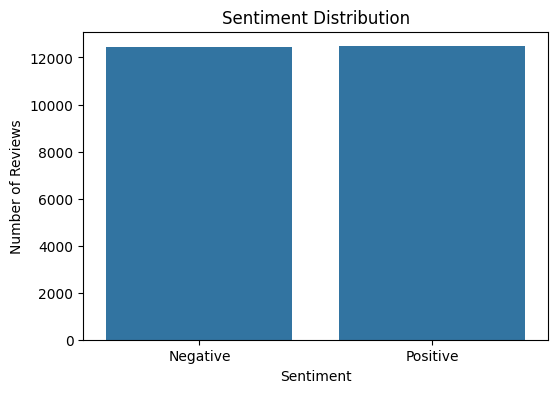

In [9]:
plt.figure(figsize=(6,4))

sns.countplot(data=train_df, x="label")

plt.xticks([0, 1], ["Negative", "Positive"])
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [10]:
train_df["review_length"] = train_df["text"].apply(
    lambda x: len(x.split())
)

train_df.head()

,text,label,review_length
0,I rented I AM CURIOUS-YELLOW from my video sto...,0,288
1,"""I Am Curious: Yellow"" is a risible and preten...",0,214
2,If only to avoid making this type of film in t...,0,93
3,This film was probably inspired by Godard's Ma...,0,118
4,"Oh, brother...after hearing about this ridicul...",0,311


In [11]:
train_df["review_length"].describe()

,review_length
count,24904.000000
mean,234.005702
std,173.908379
min,10.000000
25%,127.000000
50%,174.000000
75%,285.000000
max,2470.000000


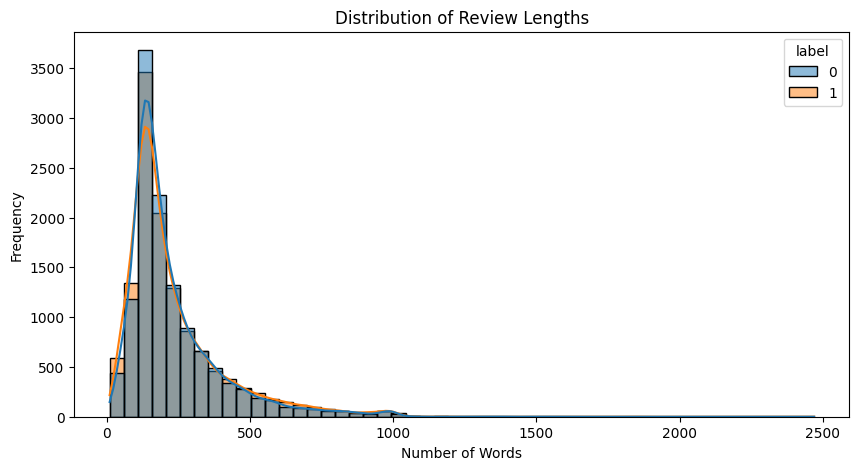

In [12]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=train_df,
    x="review_length",
    hue="label",
    bins=50,
    kde=True
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [13]:
train_df.groupby("label")["review_length"].mean()

,review_length
label,
0,231.077542
1,236.924471


In [14]:
print("POSITIVE REVIEW:\n")

print(
    train_df[train_df["label"] == 1]
    ["text"].iloc[0]
)

print("\nNEGATIVE REVIEW:\n")

print(
    train_df[train_df["label"] == 0]
    ["text"].iloc[0]
)

POSITIVE REVIEW:

Zentropa has much in common with The Third Man, another noir-like film set among the rubble of postwar Europe. Like TTM, there is much inventive camera work. There is an innocent American who gets emotionally involved with a woman he doesn't really understand, and whose naivety is all the more striking in contrast with the natives.<br /><br />But I'd have to say that The Third Man has a more well-crafted storyline. Zentropa is a bit disjointed in this respect. Perhaps this is intentional: it is presented as a dream/nightmare, and making it too coherent would spoil the effect. <br /><br />This movie is unrelentingly grim--"noir" in more than one sense; one never sees the sun shine. Grim, but intriguing, and frightening.

NEGATIVE REVIEW:

I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, th

In [15]:
import re
import string
from bs4 import BeautifulSoup

In [16]:
!pip install beautifulsoup4

In [17]:
def remove_html(text):
    soup = BeautifulSoup(text, "html.parser")
    return soup.get_text()

In [18]:
sample = "This movie is great! <br /> Amazing acting."

print(remove_html(sample))

This movie is great!  Amazing acting.


In [19]:
def lowercase(text):
    return text.lower()

In [20]:
print(lowercase("THIS MOVIE IS AMAZING"))

this movie is amazing


In [21]:
def remove_special_chars(text):
    text = re.sub(r"[^a-zA-Z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [22]:
sample = "Amazing movie!!! Rating: 10/10."

print(remove_special_chars(sample))

Amazing movie Rating 10 10


In [23]:
def preprocess_text(text):

    text = remove_html(text)
    text = lowercase(text)
    text = remove_special_chars(text)

    return text

In [24]:
sample = """
THIS movie was <br /> absolutely AMAZING!!!
I don't regret watching it.
"""

print(preprocess_text(sample))

this movie was absolutely amazing i don't regret watching it


In [25]:
train_df["clean_text"] = train_df["text"].apply(preprocess_text)

test_df["clean_text"] = test_df["text"].apply(preprocess_text)

In [26]:
print("Original:")
print(train_df["text"].iloc[0])

print("\nCleaned:")
print(train_df["clean_text"].iloc[0])

Original:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far be

In [27]:
print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print("\nMissing cleaned reviews:")
print(train_df["clean_text"].isnull().sum())

print("\nSample cleaned review:")
print(train_df["clean_text"].iloc[0])

Training samples: 24904
Testing samples: 24801

Missing cleaned reviews:
0

Sample cleaned review:
i rented i am curious yellow from my video store because of all the controversy that surrounded it when it was first released in 1967 i also heard that at first it was seized by u s customs if it ever tried to enter this country therefore being a fan of films considered controversial i really had to see this for myself the plot is centered around a young swedish drama student named lena who wants to learn everything she can about life in particular she wants to focus her attentions to making some sort of documentary on what the average swede thought about certain political issues such as the vietnam war and race issues in the united states in between asking politicians and ordinary denizens of stockholm about their opinions on politics she has sex with her drama teacher classmates and married men what kills me about i am curious yellow is that 40 years ago this was considered pornographic

**NLP**

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [29]:
X_train = train_df["clean_text"]
y_train = train_df["label"]

X_test = test_df["clean_text"]
y_test = test_df["label"]

In [30]:
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

In [31]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

In [32]:
print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (24904, 20000)
Testing shape: (24801, 20000)


In [33]:
print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (24904, 20000)
Testing shape: (24801, 20000)


In [34]:
print(X_train_tfidf[0])

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 269 stored elements and shape (1, 20000)>
  Coords	Values
  (0, 13463)	0.05593489900703837
  (0, 693)	0.10654070997096518
  (0, 3984)	0.17717495911442538
  (0, 19834)	0.20898787576442468
  (0, 6251)	0.018429973273868375
  (0, 10889)	0.04455267897602631
  (0, 18509)	0.04085465828302815
  (0, 15163)	0.05216708365938913
  (0, 2148)	0.02500007863731268
  (0, 11420)	0.06616953619233289
  (0, 546)	0.017270318921726435
  (0, 3745)	0.07601656304949576
  (0, 15706)	0.05060270388588334
  (0, 15441)	0.0652546199919018
  (0, 8668)	0.07012208414380645
  (0, 19150)	0.0211524467590416
  (0, 18669)	0.04514386705886144
  (0, 5906)	0.049446002880188786
  (0, 13400)	0.045313068744049896
  (0, 7953)	0.11801901845932145
  (0, 55)	0.07558863846178959
  (0, 642)	0.02465770881722635
  (0, 7276)	0.043926440441076346
  (0, 1751)	0.017381085402909467
  (0, 2843)	0.0184120219094141
  :	:
  (0, 16206)	0.02350033215299218
  (0, 5754)	0.031584339922489255

In [35]:
print(list(tfidf.vocabulary_.items())[:20])

[('rented', np.int64(13463)), ('am', np.int64(693)), ('curious', np.int64(3984)), ('yellow', np.int64(19834)), ('from', np.int64(6251)), ('my', np.int64(10889)), ('video', np.int64(18509)), ('store', np.int64(15163)), ('because', np.int64(2148)), ('of', np.int64(11420)), ('all', np.int64(546)), ('controversy', np.int64(3745)), ('that', np.int64(15706)), ('surrounded', np.int64(15441)), ('it', np.int64(8668)), ('when', np.int64(19150)), ('was', np.int64(18669)), ('first', np.int64(5906)), ('released', np.int64(13400)), ('in', np.int64(7953))]


In [36]:
feature_names = tfidf.get_feature_names_out()

row = X_train_tfidf[0].toarray().flatten()

top_indices = row.argsort()[-10:][::-1]

for idx in top_indices:
    print(feature_names[idx], row[idx])

swedish 0.21573842648080674
sex 0.21123944994110783
yellow 0.20898787576442468
curious 0.17717495911442538
shown 0.13682712772496014
shown in 0.12527513146358848
sex and 0.12503275427366115
in 0.11801901845932145
issues 0.11002414420780776
am 0.10654070997096518


In [37]:
model = LogisticRegression(
    max_iter=1000,
    C=1.0
)

model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [38]:
y_pred = model.predict(X_test_tfidf)

In [39]:
for i in range(5):
    print("Actual:", y_test.iloc[i])
    print("Predicted:", y_pred[i])
    print()

Actual: 0
Predicted: 0

Actual: 0
Predicted: 0

Actual: 0
Predicted: 0

Actual: 0
Predicted: 0

Actual: 0
Predicted: 1



In [40]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8963348252086609


In [41]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.90      0.89      0.90     12361
    Positive       0.89      0.90      0.90     12440

    accuracy                           0.90     24801
   macro avg       0.90      0.90      0.90     24801
weighted avg       0.90      0.90      0.90     24801



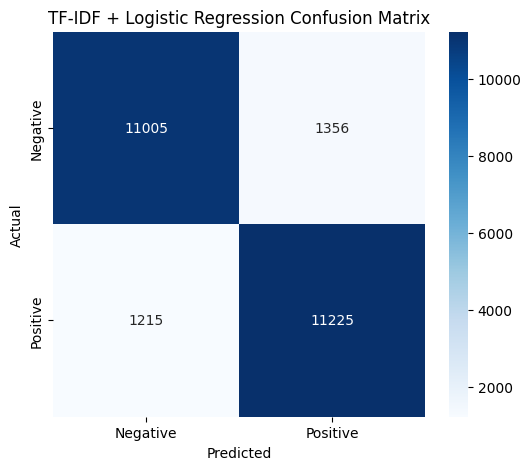

In [42]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("TF-IDF + Logistic Regression Confusion Matrix")

plt.show()

In [43]:
review = "This movie was absolutely fantastic. I loved the acting."

cleaned_review = preprocess_text(review)

review_vector = tfidf.transform([cleaned_review])

prediction = model.predict(review_vector)

if prediction[0] == 1:
    print("Positive Sentiment")
else:
    print("Negative Sentiment")

Positive Sentiment


In [44]:
import joblib

joblib.dump(model, "tfidf_logistic_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']

In [45]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    LSTM,
    Bidirectional,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split

import time

In [2]:
import tensorflow as tf
print(tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))

2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [9]:
from tensorflow.keras.preprocessing.text import Tokenizer
import pandas as pd
from datasets import load_dataset
import re
from bs4 import BeautifulSoup

# Define the preprocessing functions since they were cleared during the runtime restart
def remove_html(text):
    soup = BeautifulSoup(text, "html.parser")
    return soup.get_text()

def lowercase(text):
    return text.lower()

def remove_special_chars(text):
    text = re.sub(r"[^a-zA-Z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def preprocess_text(text):
    text = remove_html(text)
    text = lowercase(text)
    text = remove_special_chars(text)
    return text

# 1. Re-load and clean dataset
dataset = load_dataset("stanfordnlp/imdb")
train_df = pd.DataFrame(dataset["train"]).drop_duplicates(subset=["text"], keep="first")
test_df = pd.DataFrame(dataset["test"]).drop_duplicates(subset=["text"], keep="first")

# Re-apply text cleaning
train_df["clean_text"] = train_df["text"].apply(preprocess_text)
test_df["clean_text"] = test_df["text"].apply(preprocess_text)

X_train = train_df["clean_text"]
X_test = test_df["clean_text"]
y_train = train_df["label"]
y_test = test_df["label"]

# 2. Tokenizer setup and fitting
MAX_WORDS = 20000

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

print("Vocabulary size:", len(tokenizer.word_index))

Vocabulary size: 88242


In [10]:
import warnings
import logging

# Suppress UserWarnings and Hugging Face logger outputs for unauthenticated requests
warnings.filterwarnings("ignore", category=UserWarning)
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

In [11]:
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

In [12]:
print("Original:", X_train.iloc[0])
print("Sequence:", X_train_seq[0])

Original: i rented i am curious yellow from my video store because of all the controversy that surrounded it when it was first released in 1967 i also heard that at first it was seized by u s customs if it ever tried to enter this country therefore being a fan of films considered controversial i really had to see this for myself the plot is centered around a young swedish drama student named lena who wants to learn everything she can about life in particular she wants to focus her attentions to making some sort of documentary on what the average swede thought about certain political issues such as the vietnam war and race issues in the united states in between asking politicians and ordinary denizens of stockholm about their opinions on politics she has sex with her drama teacher classmates and married men what kills me about i am curious yellow is that 40 years ago this was considered pornographic really the sex and nudity scenes are few and far between even then it's not shot like so

In [14]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LEN = 300

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

In [15]:
print(X_train_pad.shape)
print(X_test_pad.shape)

(24904, 300)
(24801, 300)


In [17]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_pad,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

BiLSTM

In [27]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding,Input, Bidirectional, LSTM, Dropout, Dense

model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=128,
        mask_zero=True
    ),
    Bidirectional(
        LSTM(64)
    ),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

In [21]:
Bidirectional(LSTM(64))

<Bidirectional name=bidirectional_1, built=False>

In [22]:
Dropout(0.5)

<Dropout name=dropout_1, built=True>

In [23]:
Dense(1, activation="sigmoid")

<Dense name=dense_1, built=False>

In [29]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [30]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 300, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,658,945 (10.14 MB)

 Trainable params: 2,658,945 (10.14 MB)

 Non-trainable params: 0 (0.00 B)

In [32]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

In [34]:
import time

start_time = time.time()

history = model.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

training_time = time.time() - start_time

print("Training time:", training_time, "seconds")

Epoch 1/5
312/312 ━━━━━━━━━━━━━━━━━━━━ 31s 63ms/step - accuracy: 0.7734 - loss: 0.4679 - val_accuracy: 0.8151 - val_loss: 0.4034
Epoch 2/5
312/312 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - accuracy: 0.9087 - loss: 0.2337 - val_accuracy: 0.8759 - val_loss: 0.2999
Epoch 3/5
312/312 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9390 - loss: 0.1647 - val_accuracy: 0.8522 - val_loss: 0.3857
Epoch 4/5
312/312 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.9692 - loss: 0.0920 - val_accuracy: 0.8661 - val_loss: 0.4015
Training time: 64.44609332084656 seconds


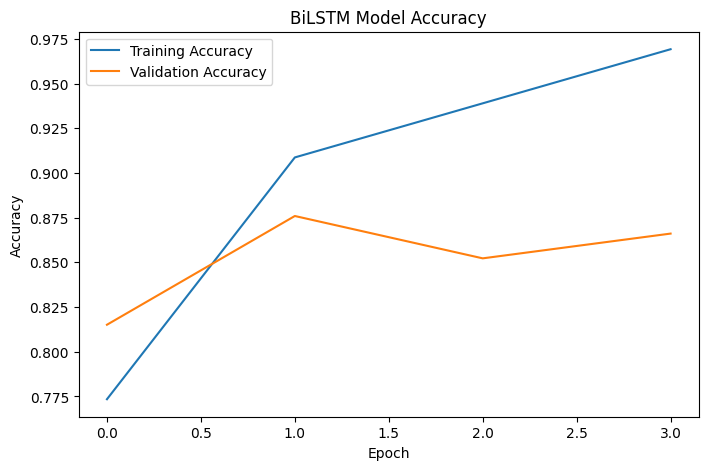

In [36]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("BiLSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [37]:
# Split raw reviews first
X_train_raw, X_val_raw, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Fit tokenizer only on training reviews
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_raw)

# Convert all datasets into sequences
X_train_seq = tokenizer.texts_to_sequences(X_train_raw)
X_val_seq = tokenizer.texts_to_sequences(X_val_raw)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Padding
X_train_final = pad_sequences(
    X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

X_val = pad_sequences(
    X_val_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

y_train_final = y_train_final.to_numpy()
y_val = y_val.to_numpy()

In [38]:
model.save("bilstm_sentiment_model.keras")

In [39]:
import numpy as np
import time

start_time = time.time()

y_pred_prob = model.predict(X_test_pad)

prediction_time = time.time() - start_time

y_pred_bilstm = (y_pred_prob >= 0.5).astype(int).flatten()

776/776 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step


In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [41]:
bilstm_accuracy = accuracy_score(y_test, y_pred_bilstm)

bilstm_precision = precision_score(y_test, y_pred_bilstm)

bilstm_recall = recall_score(y_test, y_pred_bilstm)

bilstm_f1 = f1_score(y_test, y_pred_bilstm)

print("BiLSTM Accuracy:", bilstm_accuracy)
print("BiLSTM Precision:", bilstm_precision)
print("BiLSTM Recall:", bilstm_recall)
print("BiLSTM F1 Score:", bilstm_f1)

BiLSTM Accuracy: 0.5714285714285714
BiLSTM Precision: 0.5778924731182795
BiLSTM Recall: 0.5400321543408361
BiLSTM F1 Score: 0.5583212133804281


In [42]:
print(classification_report(
    y_test,
    y_pred_bilstm,
    target_names=["Negative", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.57      0.60      0.58     12361
    Positive       0.58      0.54      0.56     12440

    accuracy                           0.57     24801
   macro avg       0.57      0.57      0.57     24801
weighted avg       0.57      0.57      0.57     24801



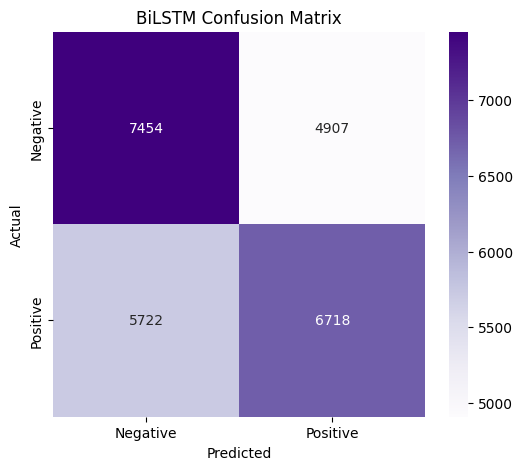

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_bilstm = confusion_matrix(y_test, y_pred_bilstm)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_bilstm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("BiLSTM Confusion Matrix")

plt.show()

In [46]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Re-initialize and fit the TF-IDF vectorizer directly in memory
tfidf_vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# 2. Train the Logistic Regression model in memory
lr_model = LogisticRegression(max_iter=1000, C=1.0)
lr_model.fit(X_train_tfidf, y_train)

# 3. Predict and compute metrics
y_pred = lr_model.predict(X_test_tfidf)
accuracy = accuracy_score(y_test, y_pred)

# 4. Construct comparison DataFrame
results = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "BiLSTM"
    ],
    "Accuracy": [
        accuracy,
        bilstm_accuracy
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        bilstm_precision
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        bilstm_recall
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        bilstm_f1
    ]
})

print(results)

                          Model  Accuracy  Precision    Recall  F1 Score
0  TF-IDF + Logistic Regression  0.896174   0.891997  0.902251  0.897095
1                        BiLSTM  0.571429   0.577892  0.540032  0.558321


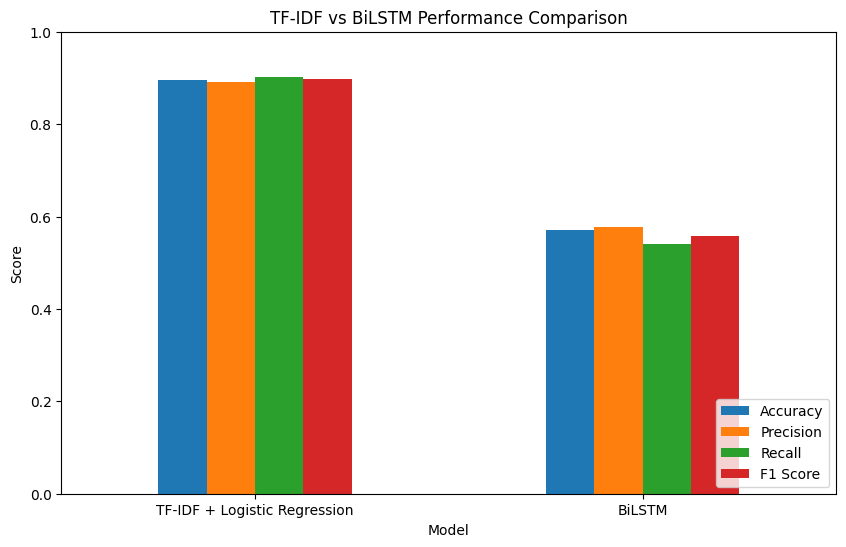

In [47]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("TF-IDF vs BiLSTM Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

In [49]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

In [50]:
start_time = time.time()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

model_tfidf = LogisticRegression(max_iter=1000)
model_tfidf.fit(X_train_tfidf, y_train)

tfidf_training_time = time.time() - start_time

In [51]:
reviews = [
    "This movie was absolutely fantastic. I loved it.",
    "The movie was boring and a complete waste of time.",
    "The acting was good but the story was terrible.",
    "One of the best movies I have ever watched."
]

In [53]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Preprocess the raw texts
cleaned_reviews = [preprocess_text(r) for r in reviews]

# --- TF-IDF + Logistic Regression Inference ---
tfidf_vectors = tfidf.transform(cleaned_reviews)
tfidf_predictions = model_tfidf.predict(tfidf_vectors)
print("TF-IDF Logistic Regression Predictions:", tfidf_predictions)

# --- BiLSTM Inference ---
# Convert cleaned reviews to token sequences and pad them to MAX_LEN (300)
review_seqs = tokenizer.texts_to_sequences(cleaned_reviews)
review_padded = pad_sequences(review_seqs, maxlen=MAX_LEN, padding="post", truncating="post")

# Predict using the deep learning BiLSTM model
bilstm_pred_probs = model.predict(review_padded)
bilstm_predictions = (bilstm_pred_probs >= 0.5).astype(int).flatten()
print("BiLSTM Predictions:", bilstm_predictions)

TF-IDF Logistic Regression Predictions: [1 0 0 1]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
BiLSTM Predictions: [0 0 1 1]


In [54]:
for i, review in enumerate(reviews):

    print("\nReview:", review)

    print("TF-IDF:",
          "Positive" if tfidf_predictions[i] == 1 else "Negative")

    print("BiLSTM:",
          "Positive" if bilstm_predictions[i] == 1 else "Negative")


Review: This movie was absolutely fantastic. I loved it.
TF-IDF: Positive
BiLSTM: Negative

Review: The movie was boring and a complete waste of time.
TF-IDF: Negative
BiLSTM: Negative

Review: The acting was good but the story was terrible.
TF-IDF: Negative
BiLSTM: Positive

Review: One of the best movies I have ever watched.
TF-IDF: Positive
BiLSTM: Positive


MODEL PERFORMANCE COMPARISON


,TF-IDF + Logistic Regression,BiLSTM
Accuracy,0.8962,0.5714
Precision,0.8920,0.5779
Recall,0.9023,0.5400
F1 Score,0.8971,0.5583


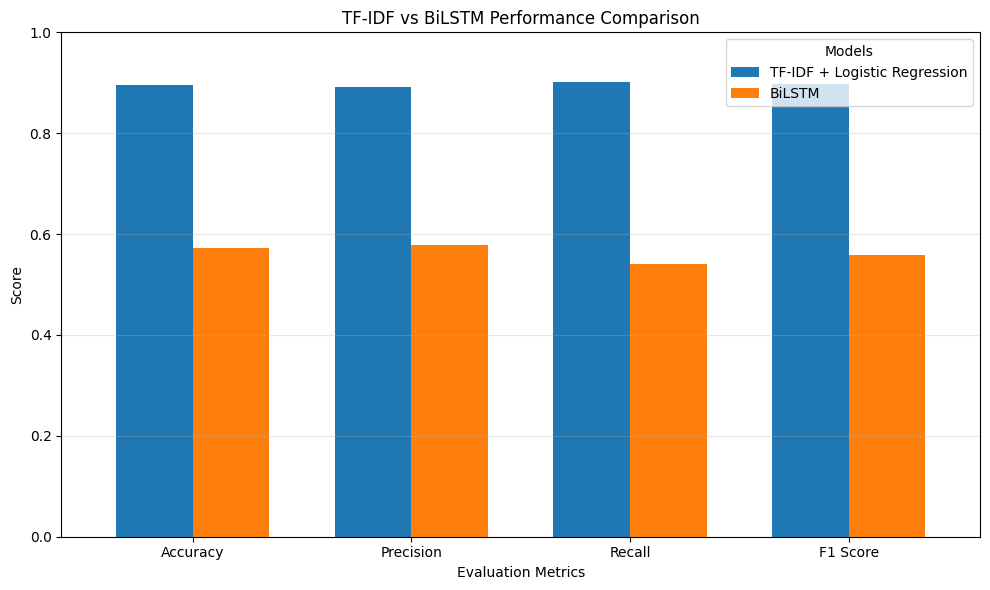


TRAINING TIME COMPARISON


,Model,Training Time (seconds)
0,TF-IDF + Logistic Regression,25.34
1,BiLSTM,64.45


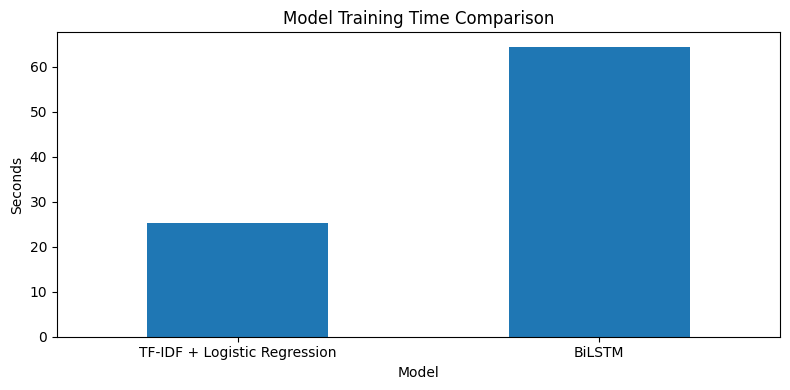

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate TF-IDF metrics
tfidf_results = {
    "Accuracy": accuracy_score(y_test, tfidf_predictions if len(tfidf_predictions) == len(y_test) else y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred)
}

# Calculate BiLSTM metrics
bilstm_results = {
    "Accuracy": accuracy_score(y_test, y_pred_bilstm),
    "Precision": precision_score(y_test, y_pred_bilstm),
    "Recall": recall_score(y_test, y_pred_bilstm),
    "F1 Score": f1_score(y_test, y_pred_bilstm)
}

# Create comparison table
comparison = pd.DataFrame({
    "TF-IDF + Logistic Regression": tfidf_results,
    "BiLSTM": bilstm_results
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(4))

# Plot comparison
comparison.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    width=0.7
)

plt.title("TF-IDF vs BiLSTM Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.xticks(rotation=0)
plt.legend(title="Models")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Training time comparison
time_comparison = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "BiLSTM"
    ],
    "Training Time (seconds)": [
        tfidf_training_time,
        training_time
    ]
})

print("\nTRAINING TIME COMPARISON")
display(time_comparison.round(2))

time_comparison.plot(
    x="Model",
    y="Training Time (seconds)",
    kind="bar",
    legend=False,
    figsize=(8, 4)
)

plt.title("Model Training Time Comparison")
plt.ylabel("Seconds")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()